# 06 – Galutinis modelių palyginimas TEST rinkinyje

Šiame Notebook vieną kartą galutiniame TEST rinkinyje palyginami DEV etape užfiksuoti modeliai:

- sezoninis atskaitos metodas (**Baseline**);
- **MLP**;
- **CatBoost**;
- optimizuotas **Voting Ensemble**;
- lengvas **N-BEATS tipo modelis**.

## Galutinio palyginimo principas

Modelių architektūros ir hiperparametrai jau parinkti ankstesniuose DEV eksperimentuose. Šiame etape pagal TEST **niekas nebeoptimizuojama ir nekeičiama**.

Galutiniam vertinimui užfiksuoti modeliai apmokomi DEV duomenimis ir vieną kartą vertinami tame pačiame TEST laikotarpyje.

Pagrindinis palyginimo kriterijus – **MAE**. RMSE naudojama papildomam bendros klaidos vertinimui, Peak MAE – klaidoms piko metu, o PUR paliekamas tik kaip papildomas piko neįvertinimo diagnostinis rodiklis.

### N-BEATS galutinio mokymo taisyklė

05 Notebook DEV etape `early stopping` naudojamas modelio paieškai ir mokymo trukmei įvertinti. Galutiniame 06 etape N-BEATS **nebenaudoja TEST ir neatideda dalies DEV naujam modelio parinkimui**. Mokymo epochų skaičius paimamas iš DEV etapo, jei jis išsaugotas `best_nbeats.json`. Jei senesniame 05 faile epochų skaičius dar neišsaugotas, naudojamas iš anksto nustatytas **80 epochų** galutinis mokymas – toks pats maksimalus mokymo biudžetas kaip 05 eksperimente. Ši reikšmė nėra parenkama pagal TEST.

In [1]:
from pathlib import Path
import sys, warnings, json
warnings.filterwarnings("ignore")
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA_PATH = ROOT / "hour.csv"
RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)
from src.common import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor
from catboost import CatBoostRegressor
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
torch.manual_seed(SEED)
work=load_prepare(DATA_PATH); FEATURES=feature_columns(work); dev,test=split_dev_test(work)
display(pd.Series(leakage_report(work,dev,test,FEATURES)))

# Skaičiavimo įrenginys N-BEATS modeliui.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

from IPython.display import display, Markdown


chronological_sorted          True
target_after_feature_time     True
casual_in_features           False
registered_in_features       False
dev_before_test               True
test_rows                      714
dev_rows                     16295
dtype: object

## Kodėl šiuo TEST palyginimu galima pasitikėti?

Šio etapo paskirtis – nebeieškoti geresnių parametrų, o vienodomis sąlygomis patikrinti jau DEV dalyje užfiksuotus sprendimus. Jei pamačius TEST rezultatą būtų grįžtama atgal ir keičiami modelio parametrai, požymiai ar ansamblio svoriai, tas pats TEST nebegalėtų būti laikomas nepriklausomu galutiniu testu.

Todėl šiame Notebook:
- naudojamas tas pats TEST laikotarpis visiems modeliams;
- naudojamos tos pačios MAE, RMSE, Peak MAE ir PUR skaičiavimo taisyklės;
- piko slenkstis nustatomas iš DEV, ne iš TEST;
- modelių konfigūracijos paimamos iš ankstesnių DEV eksperimentų;
- `casual` ir `registered` nepatenka į požymius;
- rezultatai interpretuojami tik po realaus kodo paleidimo.

Jei po TEST palyginimo nusprendžiama kurti naują modelio variantą, sąžiningam galutiniam įvertinimui reikėtų naujo, anksčiau nenaudoto testavimo laikotarpio.

## 1. DEV dalyje užfiksuotų konfigūracijų nuskaitymas

In [2]:
from IPython.display import display, Markdown

def load_json(name, default=None):
    p = RESULTS / name
    if p.exists():
        return json.loads(p.read_text(encoding="utf-8"))
    if default is not None:
        return default
    raise FileNotFoundError(
        f"Trūksta {p}. Pirmiausia paleiskite atitinkamą DEV eksperimento Notebook."
    )

mlp_cfg = load_json(
    "best_mlp.json",
    {"hidden":[64,64,32], "alpha":0.0001, "lr":0.001}
)
cat_cfg = load_json("best_catboost.json")
vote_cfg = load_json("best_voting.json")
n_cfg = load_json("best_nbeats.json")

display(pd.DataFrame([
    {"Modelis":"MLP", "DEV užfiksuota konfigūracija":str(mlp_cfg)},
    {"Modelis":"CatBoost", "DEV užfiksuota konfigūracija":str(cat_cfg)},
    {"Modelis":"Voting Ensemble", "DEV užfiksuota konfigūracija":str(vote_cfg)},
    {"Modelis":"N-BEATS", "DEV užfiksuota konfigūracija":str(n_cfg)}
]))

print("TEST šiame etape naudojamas tik galutiniam užfiksuotų modelių įvertinimui.")


,Modelis,DEV užfiksuota konfigūracija
0,MLP,"{'hidden': [64, 64, 32], 'alpha': 0.0001, 'lr'..."
1,CatBoost,"{'depth': 9, 'iterations': 700, 'lr': 0.05}"
2,Voting Ensemble,"{'gbr': {'n_estimators': 500, 'learning_rate':..."
3,N-BEATS,"{'hidden': 128, 'blocks': 2, 'lr': 0.001, 'loo..."


TEST šiame etape naudojamas tik galutiniam užfiksuotų modelių įvertinimui.


## 2. Baseline TEST

In [3]:
peak=float(dev["target"].quantile(PEAK_Q))
preds={}
preds["Baseline"]=seasonal_baseline(dev,test,4)

## 3. MLP, CatBoost ir Voting TEST

In [4]:
# MLP – ta pati DEV etape užfiksuota konfigūracija.
mlp = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc", StandardScaler()),
    ("mlp", MLPRegressor(
        hidden_layer_sizes=tuple(mlp_cfg["hidden"]),
        alpha=float(mlp_cfg["alpha"]),
        learning_rate_init=float(mlp_cfg["lr"]),
        max_iter=400,
        early_stopping=True,
        validation_fraction=0.15,
        random_state=SEED
    ))
])
mlp.fit(dev[FEATURES], dev["target"])
preds["MLP"] = mlp.predict(test[FEATURES])

# CatBoost – naudojami tik 03 Notebook DEV etape išsaugoti parametrai.
cat_params = {
    "depth": int(cat_cfg["depth"]),
    "iterations": int(cat_cfg["iterations"]),
    "learning_rate": float(cat_cfg.get("lr", cat_cfg.get("learning_rate"))),
    "loss_function": "RMSE",
    "verbose": False,
    "random_seed": SEED,
    "allow_writing_files": False
}
for key in ["l2_leaf_reg", "random_strength", "bagging_temperature"]:
    if key in cat_cfg:
        cat_params[key] = float(cat_cfg[key])

cat = CatBoostRegressor(**cat_params)
cat.fit(dev[FEATURES], dev["target"])
preds["CatBoost"] = cat.predict(test[FEATURES])

# Voting – išlaikoma ankstesnio 06 logika:
# vienas DEV etape parinktas svoris w ir antras svoris (1-w).
vote_imputer = SimpleImputer(strategy="median")
Xdev_vote = vote_imputer.fit_transform(dev[FEATURES])
Xtest_vote = vote_imputer.transform(test[FEATURES])

g = GradientBoostingRegressor(random_state=SEED, **vote_cfg["gbr"])
h = HistGradientBoostingRegressor(random_state=SEED, **vote_cfg["hgbr"])
g.fit(Xdev_vote, dev["target"])
h.fit(Xdev_vote, dev["target"])

w = float(vote_cfg["w_gbr"])
preds["Voting Ensemble"] = (
    w * g.predict(Xtest_vote)
    + (1.0 - w) * h.predict(Xtest_vote)
)

print(f"Voting svoriai: GBR={w:.4f}, HGBR={1.0-w:.4f}")


Voting svoriai: GBR=0.0901, HGBR=0.9099


## 4. N-BEATS TEST

### Kodėl galutiniame N-BEATS nebenaudojamas `early stopping`?

`Early stopping` buvo reikalingas 05 DEV eksperimente, kai buvo lyginamos modelio konfigūracijos. Galutiniame TEST etape konfigūracija jau yra užfiksuota.

Todėl 06 Notebook modelis apmokomas **visomis tinkamomis DEV sekomis**, o mokymo trukmė užfiksuojama dar prieš TEST vertinimą. Taip:

- neprarandama 15 % DEV duomenų vien naujai validacijai;
- TEST nedaro jokios įtakos mokymo trukmei;
- galutinis modelis naudoja visą DEV informaciją;
- išlaikoma 05 → 06 eksperimento logika.

Jei `best_nbeats.json` yra iš senesnės 05 versijos ir neturi `final_epochs`, naudojamas 80 epochų biudžetas. Tai yra iš anksto nustatyta reikšmė, o ne sprendimas pagal TEST rezultatą.

In [5]:
from IPython.display import display, Markdown

# --- N-BEATS tipo modelis: galutinis apmokymas visoje DEV dalyje ---

# Apsauginė inicializacija, kad celė veiktų ir paleista atskirai.
if "DEVICE" not in globals():
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


class Block(nn.Module):
    def __init__(self, backcast_len=24, hidden=128):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(backcast_len, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU()
        )
        self.back = nn.Linear(hidden, backcast_len)
        self.fore = nn.Linear(hidden, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.back(h), self.fore(h)


class NBEATS(nn.Module):
    def __init__(self, backcast_len=24, hidden=128, blocks=3):
        super().__init__()
        self.blocks = nn.ModuleList(
            [Block(backcast_len, hidden) for _ in range(blocks)]
        )

    def forward(self, x):
        residual = x
        forecast = torch.zeros(
            x.shape[0], 1,
            dtype=x.dtype,
            device=x.device
        )

        for block in self.blocks:
            back, fore = block(residual)
            residual = residual - back
            forecast = forecast + fore

        return forecast.squeeze(-1)


def seq_train(frame, lookback=24):
    """Sukuria mokymo sekas tik iš griežtai ankstesnių faktinių reikšmių."""
    history = frame.set_index("target_time")["target"].sort_index()
    X, y = [], []

    for _, row in frame.iterrows():
        t = pd.Timestamp(row["target_time"])
        vals = []
        complete = True

        for h in range(lookback, 0, -1):
            tt = t - pd.Timedelta(hours=h)
            if tt not in history.index:
                complete = False
                break
            vals.append(float(history.loc[tt]))

        if complete:
            X.append(vals)
            y.append(float(row["target"]))

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32)
    )


def seq_from_history(dev_frame, test_frame, lookback=24):
    """
    Vienos valandos į priekį TEST sekos.
    Prognozuojant laiką t naudojamos tik valandos iki t-1.
    """
    history = pd.concat([
        dev_frame[["target_time", "target"]],
        test_frame[["target_time", "target"]]
    ]).drop_duplicates("target_time")

    history = history.set_index("target_time")["target"].sort_index()

    X, y, times = [], [], []

    for _, row in test_frame.iterrows():
        t = pd.Timestamp(row["target_time"])
        vals = []
        complete = True

        for h in range(lookback, 0, -1):
            tt = t - pd.Timedelta(hours=h)
            if tt not in history.index:
                complete = False
                break
            vals.append(float(history.loc[tt]))

        if complete:
            X.append(vals)
            y.append(float(row["target"]))
            times.append(t)

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32),
        pd.to_datetime(times)
    )


lookback = int(n_cfg.get("lookback", 24))
Xtr, ytr = seq_train(dev, lookback)
Xte, yte, tte = seq_from_history(dev, test, lookback)

# Atkuriamumas.
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Mastelio parametrai skaičiuojami tik iš DEV.
mu = float(Xtr.mean())
sd = float(Xtr.std()) + 1e-8
ym = float(ytr.mean())
ys = float(ytr.std()) + 1e-8

A = torch.tensor((Xtr - mu) / sd, dtype=torch.float32)
B = torch.tensor((ytr - ym) / ys, dtype=torch.float32)
T = torch.tensor((Xte - mu) / sd, dtype=torch.float32)

model = NBEATS(
    backcast_len=lookback,
    hidden=int(n_cfg["hidden"]),
    blocks=int(n_cfg["blocks"])
).to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=float(n_cfg["lr"])
)
loss_fn = nn.L1Loss()

loader = DataLoader(
    TensorDataset(A, B),
    batch_size=256,
    shuffle=False
)

# Jei 05 Notebook išsaugojo DEV etape nustatytą epochų skaičių,
# naudojame jį. Senesniam JSON paliekamas iš anksto apibrėžtas
# 80 epochų biudžetas – TEST pagal jį niekaip nederinamas.
final_epochs = int(
    n_cfg.get(
        "final_epochs",
        n_cfg.get("epochs", 80)
    )
)

for epoch in range(final_epochs):
    model.train()
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()
        pred = model(xb)
        loss = loss_fn(pred, yb)
        loss.backward()
        optimizer.step()

model.eval()
with torch.no_grad():
    nbeats_pred = (
        model(T.to(DEVICE)).cpu().numpy() * ys + ym
    )

# Bendram palyginimui visi modeliai apribojami tomis pačiomis
# N-BEATS galiojančiomis TEST valandomis.
common_mask = test["target_time"].isin(tte).to_numpy()
test_eval = test.loc[common_mask].copy().reset_index(drop=True)

for name in list(preds.keys()):
    p = np.asarray(preds[name], dtype=float)
    if len(p) != len(test):
        raise ValueError(
            f"{name}: prognozių skaičius {len(p)} nesutampa su TEST {len(test)}."
        )
    preds[name] = p[common_mask]

nbeats_series = pd.Series(
    nbeats_pred,
    index=pd.to_datetime(tte)
)

preds["N-BEATS"] = (
    test_eval["target_time"]
    .map(nbeats_series)
    .to_numpy(dtype=float)
)

assert not np.isnan(preds["N-BEATS"]).any()

display(pd.DataFrame({
    "Rodiklis": [
        "N-BEATS DEV mokymo sekos",
        "Galutinio mokymo epochų skaičius",
        "Bendros TEST valandos"
    ],
    "Reikšmė": [
        len(Xtr),
        final_epochs,
        len(test_eval)
    ]
}))


,Rodiklis,Reikšmė
0,N-BEATS DEV mokymo sekos,13858
1,Galutinio mokymo epochų skaičius,80
2,Bendros TEST valandos,627


## 5. Galutinė TEST rezultatų lentelė

Visi modeliai vertinami tomis pačiomis TEST valandomis, kurioms galima sudaryti N-BEATS 24 valandų istorijos seką.

Vertinamos:

- **MAE** – pagrindinė galutinio palyginimo metrika;
- **RMSE** – papildoma bendros prognozavimo klaidos metrika;
- **Peak MAE** – absoliuti klaida piko valandomis;
- **PUR** – papildoma diagnostika, rodanti, kaip dažnai piko paklausa buvo neįvertinta.

Modelių eilės tvarka lentelėje nustatoma pagal MAE. PUR į modelio atrankos kriterijų neįtraukiamas.

In [6]:
from IPython.display import display, Markdown

rows = []
for name, p in preds.items():
    rows.append({
        "Modelis": name,
        **metrics(test_eval["target"], p, peak)
    })

final = (
    pd.DataFrame(rows)
    .sort_values(["MAE", "RMSE"])
    .reset_index(drop=True)
)

display(final.round({
    "MAE": 3,
    "RMSE": 3,
    "Peak_MAE": 3,
    "PUR": 3
}))

final.to_csv(
    RESULTS / "test_modeliu_palyginimas.csv",
    index=False
)

best_name = final.iloc[0]["Modelis"]
best_mae = float(final.iloc[0]["MAE"])
best_rmse_name = final.loc[final["RMSE"].idxmin(), "Modelis"]
best_peak_name = final.loc[final["Peak_MAE"].idxmin(), "Modelis"]
best_pur_name = final.loc[final["PUR"].idxmin(), "Modelis"]

display(Markdown(f"""
### Galutinio TEST palyginimo santrauka

Pagal pagrindinę metriką **MAE** geriausiai pasirodė **{best_name}** (MAE = **{best_mae:.3f}**).

- mažiausią RMSE pasiekė **{best_rmse_name}**;
- mažiausią Peak MAE pasiekė **{best_peak_name}**;
- mažiausią papildomą PUR pasiekė **{best_pur_name}**.

PUR pateikiamas kaip papildomas piko elgsenos rodiklis ir nekeičia pagal MAE daromos pagrindinės išvados.
"""))


,Modelis,MAE,RMSE,Peak_MAE,PUR,N,N_peak
0,N-BEATS,22.233,37.546,69.643,0.404,627,47
1,CatBoost,25.238,40.591,60.688,0.787,627,47
2,Voting Ensemble,27.827,42.182,68.960,0.787,627,47
3,MLP,36.775,50.592,69.533,0.638,627,47
4,Baseline,63.477,103.614,97.683,0.915,627,47



### Galutinio TEST palyginimo santrauka

Pagal pagrindinę metriką **MAE** geriausiai pasirodė **N-BEATS** (MAE = **22.233**).

- mažiausią RMSE pasiekė **N-BEATS**;
- mažiausią Peak MAE pasiekė **CatBoost**;
- mažiausią papildomą PUR pasiekė **N-BEATS**.

PUR pateikiamas kaip papildomas piko elgsenos rodiklis ir nekeičia pagal MAE daromos pagrindinės išvados.


### Metrikų palyginimas grafikuose

MAE ir RMSE parodo bendrą prognozavimo klaidą, Peak MAE – klaidą paklausos piko metu. PUR grafikas pateikiamas atskirai kaip **papildoma diagnostika**, o ne kaip modelio atrankos kriterijus.

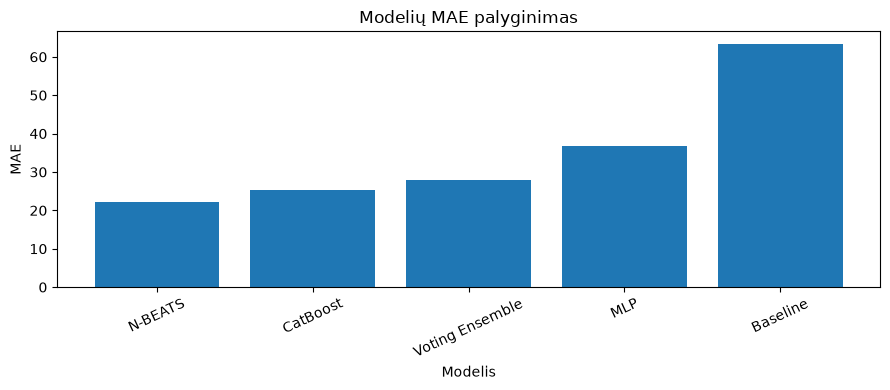

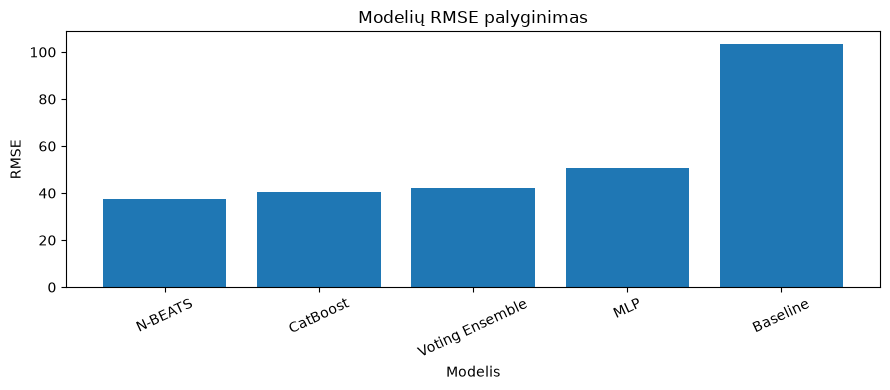

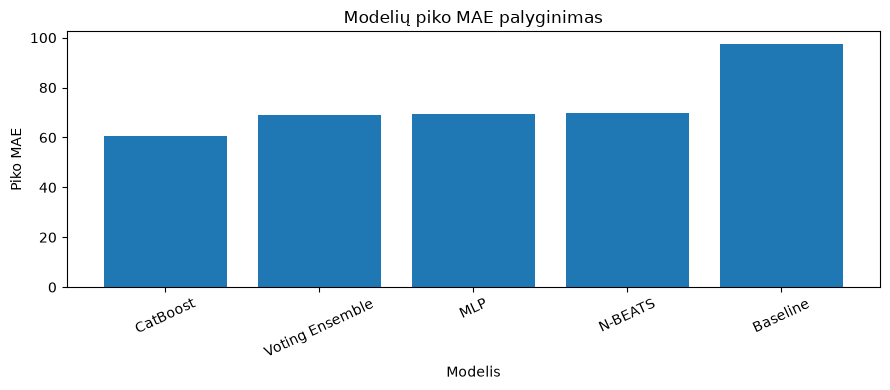

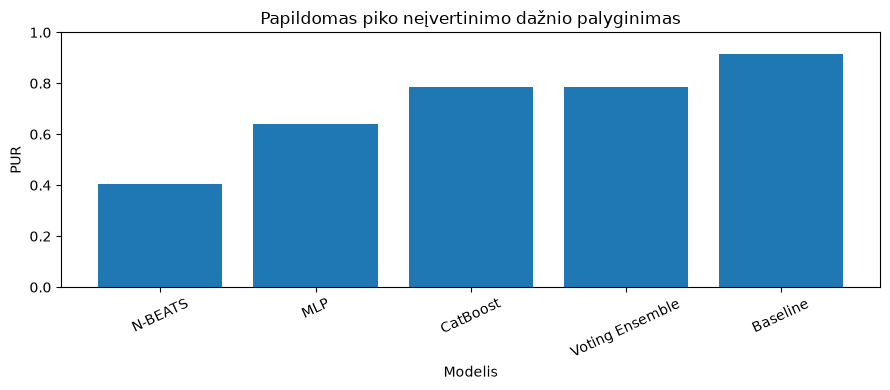

In [7]:
for metric, title, ylabel in [
    ("MAE", "Modelių MAE palyginimas", "MAE"),
    ("RMSE", "Modelių RMSE palyginimas", "RMSE"),
    ("Peak_MAE", "Modelių piko MAE palyginimas", "Piko MAE"),
    ("PUR", "Papildomas piko neįvertinimo dažnio palyginimas", "PUR")
]:
    plt.figure(figsize=(9,4))
    tmp = final.sort_values(metric)
    plt.bar(tmp["Modelis"], tmp[metric])
    plt.title(title)
    plt.xlabel("Modelis")
    plt.ylabel(ylabel)
    if metric == "PUR":
        plt.ylim(0, 1)
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()


## 6. Faktinė ir prognozuota paklausa

Metrikos sutraukia visą TEST laikotarpį į kelis skaičius, todėl papildomai tikrinama prognozių kreivė. Pirmiausia rodoma viena savaitė, kad būtų matyti, ar modeliai seka paros paklausos pikus ir kritimus.

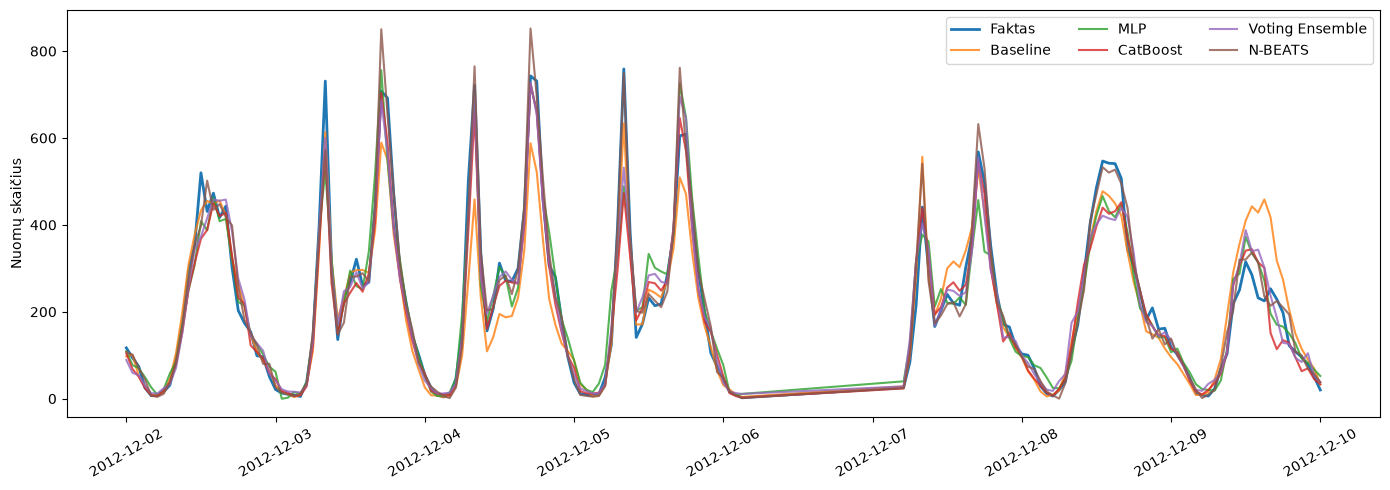

In [8]:
plt.figure(figsize=(14,5))
n=min(168,len(test_eval))
plt.plot(test_eval["target_time"].iloc[:n],test_eval["target"].iloc[:n],label="Faktas",linewidth=2)
for name,p in preds.items(): plt.plot(test_eval["target_time"].iloc[:n],p[:n],label=name,alpha=.8)
plt.legend(ncol=3); plt.xticks(rotation=30); plt.ylabel("Nuomų skaičius"); plt.tight_layout()
plt.savefig(RESULTS/"faktas_vs_prognoze.png",dpi=160,bbox_inches="tight"); plt.show()

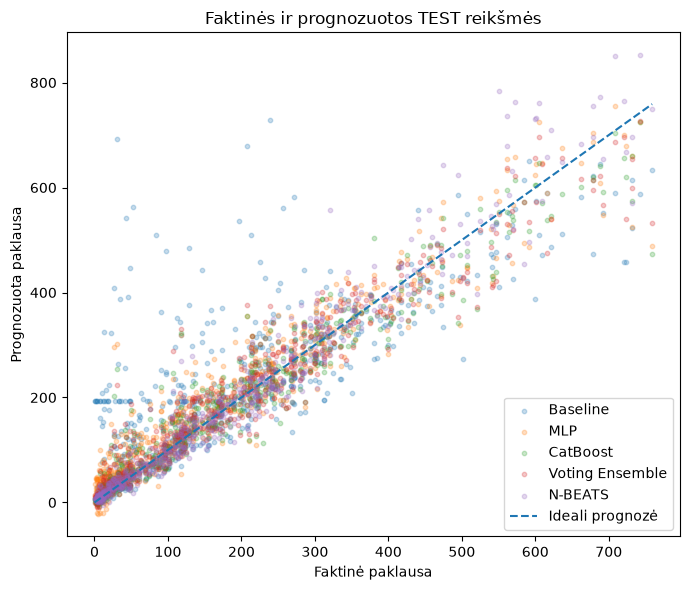

In [9]:
# Faktinė ir prognozuota reikšmė: kuo taškai arčiau įstrižainės, tuo prognozė tikslesnė.
plt.figure(figsize=(7,6))
for name,p in preds.items():
    plt.scatter(test_eval["target"],p,s=10,alpha=0.25,label=name)
mx=float(test_eval["target"].max())
plt.plot([0,mx],[0,mx],linestyle="--",label="Ideali prognozė")
plt.title("Faktinės ir prognozuotos TEST reikšmės")
plt.xlabel("Faktinė paklausa")
plt.ylabel("Prognozuota paklausa")
plt.legend()
plt.tight_layout()
plt.show()

## 7. Palyginimas su Baseline ir piko elgsena

In [10]:
from IPython.display import display, Markdown

baseline_mae = float(final.loc[final["Modelis"]=="Baseline", "MAE"].iloc[0])
best_int = final[final["Modelis"]!="Baseline"].sort_values(["MAE","RMSE"]).iloc[0]

improvement = (
    (baseline_mae - float(best_int["MAE"]))
    / baseline_mae * 100
)

selected = final[final["Modelis"]==best_int["Modelis"]].iloc[0]

display(Markdown(f"""
Geriausias intelektualusis metodas pagal TEST MAE – **{best_int["Modelis"]}**.

Jo MAE yra **{improvement:.1f} % mažesnė** už sezoninio Baseline MAE.

Piko metu šio modelio Peak MAE = **{float(selected["Peak_MAE"]):.3f}**, o papildomas PUR = **{float(selected["PUR"]):.3f}**.

Jei kitas modelis turi mažesnį PUR, tai reiškia, kad jis rečiau neįvertino piko paklausos. Tačiau šiame galutiniame palyginime pagrindinis kriterijus yra MAE, todėl PUR naudojamas tik kaip papildoma diagnostinė informacija.
"""))



Geriausias intelektualusis metodas pagal TEST MAE – **N-BEATS**.

Jo MAE yra **65.0 % mažesnė** už sezoninio Baseline MAE.

Piko metu šio modelio Peak MAE = **69.643**, o papildomas PUR = **0.404**.

Jei kitas modelis turi mažesnį PUR, tai reiškia, kad jis rečiau neįvertino piko paklausos. Tačiau šiame galutiniame palyginime pagrindinis kriterijus yra MAE, todėl PUR naudojamas tik kaip papildoma diagnostinė informacija.


## 8. Didžiausių klaidų analizė

Klaidų analizė atliekama **modeliui, kuris TEST lentelėje turi mažiausią MAE**. Tai apsaugo nuo iš anksto numatytos išvados, kad būtinai turi laimėti N-BEATS.

Rodomos konkrečios valandos, kuriomis modelis suklydo labiausiai, kartu su darbo dienos ir meteorologine informacija. Tai padeda apibūdinti modelio ribas.

Pagal TEST MAE geriausias modelis: N-BEATS


,target_time,target,hr,weekday,workingday,weathersit,temp,hum,windspeed,prognoze,absoliuti_klaida
448,2012-12-21 17:00:00,321.0,16,5,1,2,0.30,0.39,0.3284,556.809692,235.809692
256,2012-12-13 17:00:00,550.0,16,4,1,1,0.34,0.39,0.1045,784.244568,234.244568
376,2012-12-18 17:00:00,572.0,16,2,1,1,0.44,0.41,0.4627,763.097534,191.097534
232,2012-12-12 17:00:00,561.0,16,3,1,2,0.34,0.46,0.1343,736.080383,175.080383
424,2012-12-20 17:00:00,475.0,16,4,1,2,0.34,0.53,0.3284,642.872925,167.872925
32,2012-12-03 08:00:00,731.0,7,1,1,2,0.34,0.93,0.0000,570.602539,160.397461
89,2012-12-05 17:00:00,605.0,16,3,1,1,0.46,0.33,0.2836,761.620117,156.620117
426,2012-12-20 19:00:00,118.0,18,4,1,2,0.34,0.71,0.1940,269.550018,151.550018
535,2012-12-27 09:00:00,133.0,8,4,1,1,0.26,0.65,0.3582,278.956329,145.956329
41,2012-12-03 17:00:00,708.0,16,1,1,1,0.60,0.53,0.1343,850.439453,142.439453


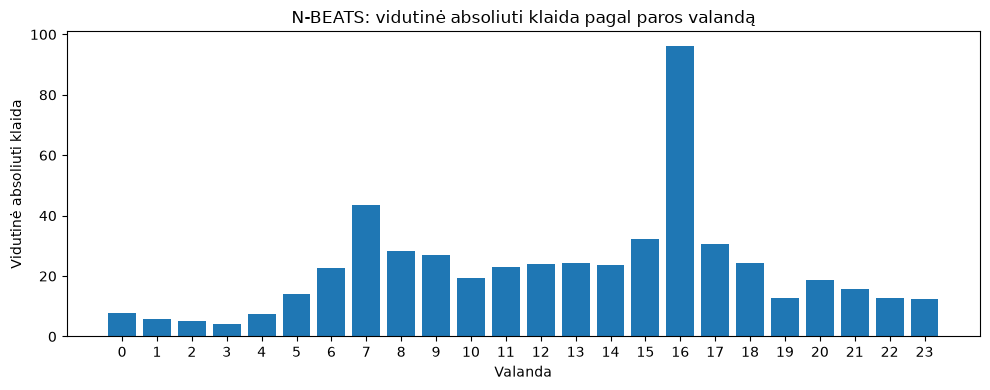

In [11]:
from IPython.display import display, Markdown

best_name=final.iloc[0]["Modelis"]
print("Pagal TEST MAE geriausias modelis:",best_name)

err=test_eval[["target_time","target","hr","weekday","workingday","weathersit","temp","hum","windspeed"]].copy()
err["prognoze"]=preds[best_name]
err["absoliuti_klaida"]=np.abs(err["target"]-err["prognoze"])
top_errors=err.nlargest(10,"absoliuti_klaida")
display(top_errors)
top_errors.to_csv(RESULTS/"geriausio_modelio_didziausios_klaidos.csv",index=False)

hour_err=err.groupby("hr")["absoliuti_klaida"].mean()
plt.figure(figsize=(10,4))
plt.bar(hour_err.index,hour_err.values)
plt.title(f"{best_name}: vidutinė absoliuti klaida pagal paros valandą")
plt.xlabel("Valanda"); plt.ylabel("Vidutinė absoliuti klaida")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

## 9. Galutinės išvados sudarymo principas

Galutinė išvada formuluojama tik pagal realiai šiame Notebook gautus TEST rezultatus.

Pirmiausia nurodoma, kuris modelis pasiekė **mažiausią MAE**. Toliau palyginamos RMSE ir Peak MAE bei įvertinama, kiek pasirinktas intelektualusis modelis pagerino rezultatą prieš sezoninį Baseline.

PUR naudojamas tik papildomai piko elgsenai aprašyti. Jei pagal MAE geriausias modelis turi prastesnį PUR už kitą modelį, tai aiškiai nurodoma kaip jo piko elgsenos ribotumas, tačiau dėl to po TEST modelis ar jo hiperparametrai nekeičiami.

Svarbu ir tai, kad galutiniame TEST **neatliekamas joks naujas hiperparametrų derinimas**. Jei galutinis rezultatas skiriasi nuo išankstinio lūkesčio, pateikiamas faktinis eksperimento rezultatas.

### Atkuriamumo pastaba

N-BEATS galutinis modelis apmokomas visu DEV rinkiniu su fiksuota atsitiktine sėkla ir iš anksto nustatytu epochų skaičiumi. Todėl galutinis TEST nėra naudojamas nei `early stopping`, nei hiperparametrų, nei mokymo trukmės parinkimui.